# Math 32 — Lecture 30: Null and Alternative Hypotheses, and the $p$-Value

Companion notebook for Lecture 30 (Standard 11: Hypothesis Testing). Every figure and number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**, so you can change a number and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

**The five steps:** (1) hypotheses, (2) level $\alpha$, (3) test statistic, (4) $p$-value, (5) conclusion in plain language.

## 1. Testing a mean: is normal body temperature 98.6°F?

$n = 65$, $\bar x = 98.35$, and the standard deviation is **known**: $\sigma = 1$. Test $H_0: \mu = 98.6$ against $H_1: \mu \neq 98.6$ (two-sided).
$$z^* = \frac{\bar x - \mu_0}{\sigma/\sqrt n}, \qquad p\text{-value} = 2\,P(Z \ge |z^*|).$$
The simulation draws temperatures from a normal distribution with the $H_0$ mean ($98.6$) and the known $\sigma = 1$, and counts how often an average of 65 temperatures lands at least as far from 98.6 as ours.

**Try it:** what if the sample had $n = 30$ women instead of 65? Is the result still significant at $\alpha = 0.05$?

standard error = 0.1240,  z = -2.016,  two-sided p-value = 0.0438


simulated p-value: 0.044125


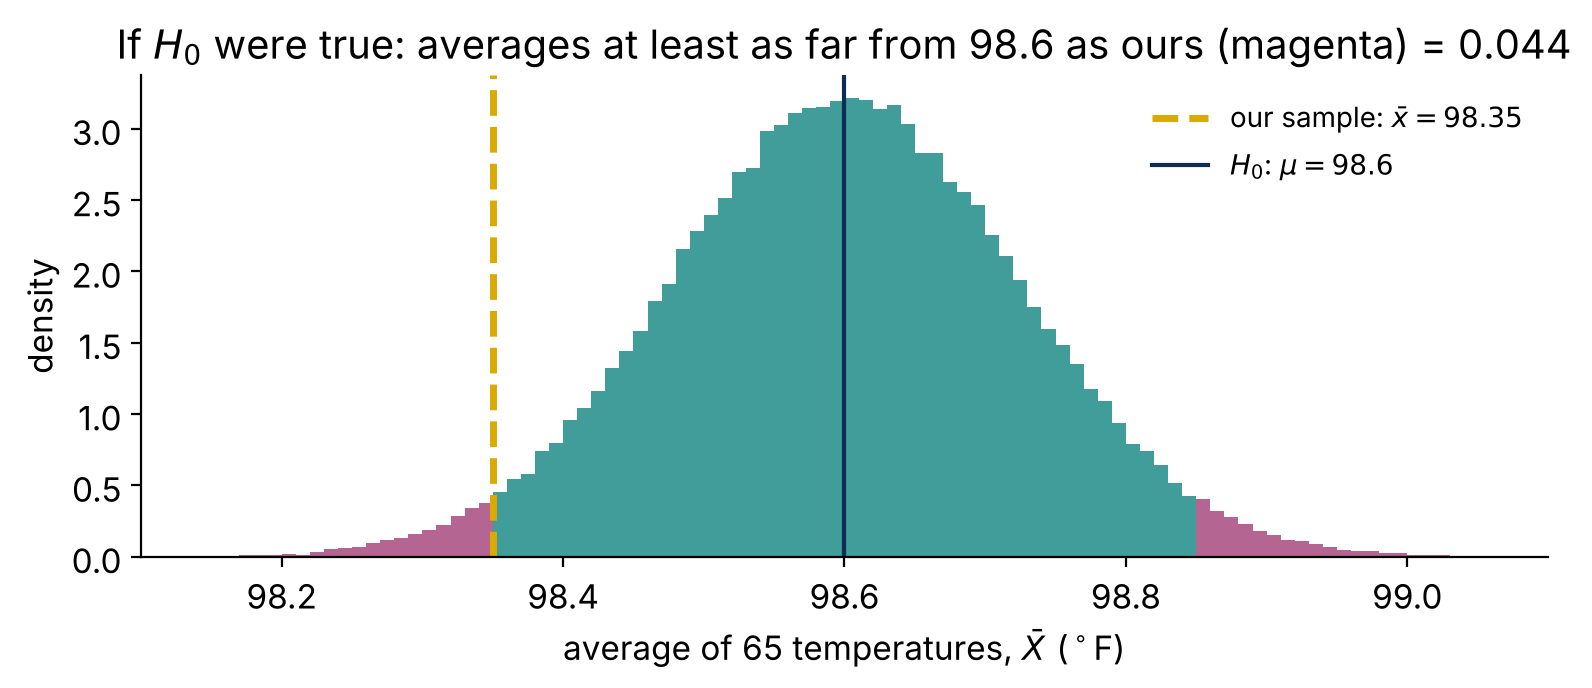

In [1]:
# Body temperature: is "normal" really 98.6 F?   n = 65, xbar = 98.35, s = 1
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, erf

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

def Phi(z):                                   # standard normal CDF
    return 0.5 * (1 + erf(z / sqrt(2)))

mu0, n, xbar, s = 98.6, 65, 98.35, 1.0     # s = the KNOWN sigma = 1
se = s / sqrt(n)
z = (xbar - mu0) / se
p_two = 2 * (1 - Phi(abs(z)))
print(f"standard error = {se:.4f},  z = {z:.3f},  two-sided p-value = {p_two:.4f}")

# If H0 were true (mu = 98.6), what averages of 65 temperatures would we see?
rng = np.random.default_rng(30)
xbars = rng.normal(mu0, s, size=(200_000, n)).mean(axis=1)
far = np.abs(xbars - mu0) >= abs(xbar - mu0)
print("simulated p-value:", far.mean())

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(98.1, 99.1, 101)
counts, edges = np.histogram(xbars, bins=bins, density=True)
centers = (edges[:-1] + edges[1:]) / 2
cols = [MAGENTA if abs(c - mu0) >= abs(xbar - mu0) else TEAL for c in centers]
ax.bar(centers, counts, width=edges[1] - edges[0], color=cols, alpha=0.75)
ax.axvline(xbar, color=GOLD, lw=2.5, ls="--", label=r"our sample: $\bar x = 98.35$")
ax.axvline(mu0, color=NAVY, lw=1.5, label=r"$H_0$: $\mu = 98.6$")
ax.set(xlim=(98.1, 99.1), xlabel=r"average of 65 temperatures, $\bar X$ ($^\circ$F)", ylabel="density",
       title=f"If $H_0$ were true: averages at least as far from 98.6 as ours (magenta) = {far.mean():.3f}")
ax.legend(frameon=False, loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "temperature_pvalue.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## 2. Testing a proportion: can the flu outbreak be contained?

In a city, the threshold for a flu **epidemic** is a 12% infection rate — anything over that, and the hospitals can't keep up.
A sample of 80 people reveals that 5 of them have the flu. Is the outbreak below the threshold?

* **Step 1:** $p$ = true proportion infected. $H_0: p = 0.12$ (the dull one: nothing has changed, we're still at the threshold) and $H_1: p < 0.12$ (one-sided, left).
* **Step 2:** $\alpha = 0.05$.
* **Step 3:** *now* use the data: $\hat p = 5/80$. For a test, the standard error uses the **claimed** value $p_0$:
$$z^* = \frac{\hat p - p_0}{\sqrt{p_0(1-p_0)/n}}.$$
* **Step 4:** $p$-value $= P(Z \le z^*)$ (left tail).

The simulation also computes the exact $p$-value by simulating samples of 80 people from a city where $p = 0.12$.

**Homework 9 (the zombie outbreak) works just like this example.**

**Try it:** what if the sample had 200 people with the same 6.25% infected (try `n = 200`, `x = 12`)? What happens to the $p$-value?


phat = 0.0625,  SE (using p0) = 0.0363,  z = -1.583,  one-sided p-value = 0.0568
simulated P(5 or fewer infected | p = 0.12): 0.070215


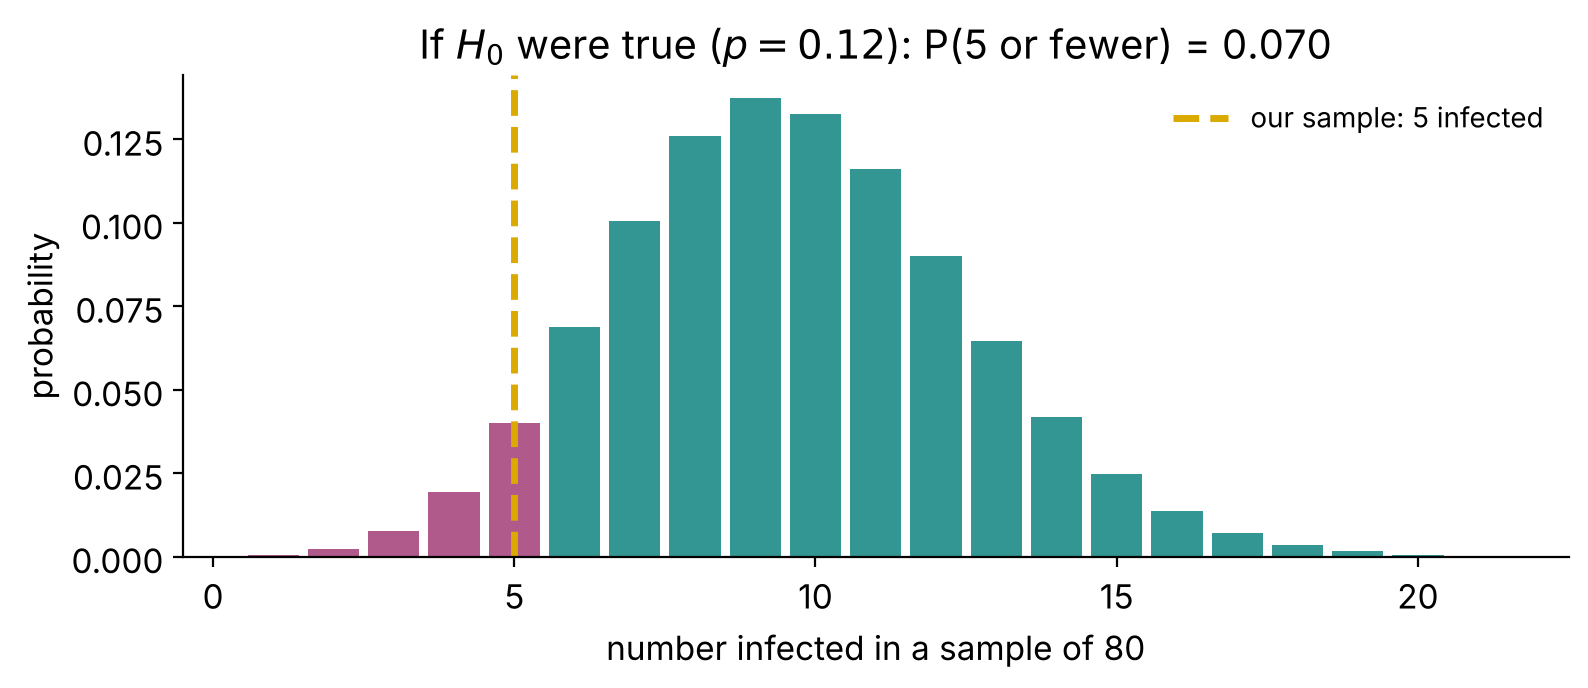

In [2]:
# Flu: the epidemic threshold is 12%.  A sample of 80 people finds 5 infected.  H0: p = 0.12 vs H1: p < 0.12
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt, erf

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

def Phi(z):
    return 0.5 * (1 + erf(z / sqrt(2)))

p0, n, x = 0.12, 80, 5
phat = x / n
se0 = sqrt(p0 * (1 - p0) / n)                 # standard error ASSUMING H0 is true (uses p0)
z = (phat - p0) / se0
p_left = Phi(z)                               # H1: p < 0.12, so the p-value is a LEFT tail
print(f"phat = {phat},  SE (using p0) = {se0:.4f},  z = {z:.3f},  one-sided p-value = {p_left:.4f}")

# If H0 were true (p = 0.12), how many infected people would a sample of 80 show?
rng = np.random.default_rng(31)
counts = rng.binomial(n, p0, size=200_000)
print("simulated P(5 or fewer infected | p = 0.12):", np.mean(counts <= x))

vals, freq = np.unique(counts, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(vals, freq / freq.sum(), width=0.85, color=[MAGENTA if v <= x else TEAL for v in vals], alpha=0.8)
ax.axvline(x, color=GOLD, lw=2.5, ls="--", label="our sample: 5 infected")
ax.set(xlim=(-0.5, 22.5), xlabel="number infected in a sample of 80", ylabel="probability",
       title=f"If $H_0$ were true ($p = 0.12$): P(5 or fewer) = {np.mean(counts <= x):.3f}")
ax.legend(frameon=False, loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "flu_pvalue.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## 3. The $p$-value is not the probability that $H_0$ is true

Here $H_0$ is **true** in every simulated study. Even so, about 5% of studies get $p \le 0.05$ — and the $p$-values are spread
evenly between 0 and 1. A small $p$-value says the *data* would be unusual if $H_0$ were true; it is not the chance that $H_0$ is true.

In [3]:
# Is the p-value the probability that H0 is true?  No!  Simulate many studies where H0 IS true.
import numpy as np
from math import sqrt, erf

def Phi(z):
    return 0.5 * (1 + erf(z / sqrt(2)))

rng = np.random.default_rng(32)
mu0, sigma, n, studies = 98.6, 1.0, 65, 100_000
xbar = rng.normal(mu0, sigma, size=(studies, n)).mean(axis=1)     # H0 is TRUE in every study
z = (xbar - mu0) / (sigma / sqrt(n))
p = 2 * (1 - np.vectorize(Phi)(np.abs(z)))
print("When H0 is true, fraction of studies with p-value <= 0.05:", np.mean(p <= 0.05))
print("  ... <= 0.01:", np.mean(p <= 0.01))
print("Average p-value when H0 is true:", p.mean(), "(p-values are spread evenly between 0 and 1)")

When H0 is true, fraction of studies with p-value <= 0.05: 0.04866
  ... <= 0.01: 0.00924
Average p-value when H0 is true: 0.5015443120152799 (p-values are spread evenly between 0 and 1)
